# Laboratorio 4: Detección de Movimiento y Seguimiento de Objetos

### Objetivo
En esta práctica, aprenderás a implementar algoritmos de detección de movimiento mediante sustracción de fondo y flujo óptico, y explorarás el filtro de Kalman para el seguimiento de objetos.

## Materiales
- **Python 3.8+**
- **OpenCV**: Puedes instalarlo con `pip install opencv-python`
- **Dataset de video**: Se usará un archivo de video o la cámara en tiempo real para probar los métodos de detección de movimiento.

In [4]:
import cv2
import os
import numpy as np
import time

## Apartado C: Sustracción de Fondo

### Tarea C.1: Carga de Video
Carga un video en el cual se detectarán objetos en movimiento. Puedes utilizar
un video local o la cámara en tiempo real.

In [5]:
#TODO: Use VideoCapture from OpenCV to read the video (visiontraffic.avi)
videopath = "../data/partC/visiontraffic.avi"  # Path to the video file
cap = cv2.VideoCapture(filename=videopath)  # Complete this line to read the video file

#TODO: Check if the video was successfully opened
if not cap.isOpened():  # Comprobamos que se abrió bien el video
    print('Error: Could not open the video file')
    os._exit(0)

#TODO: Get the szie of frames and the frame rate of the video
frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
frame_rate = cap.get(cv2.CAP_PROP_FPS)

# Añadimos un print para mostrar las características del video con el que estamos trabajando
print("Video properties:")
print(" - Width :", frame_width)
print(" - Height:", frame_height)
print(" - FPS   :", frame_rate)

#TODO: Use a loop to read the frames of the video and store them in a list
frames = []
while True:
    ret, frame = cap.read() # Esto me permite leer cada uno de los frames que componen el video (al final el vídeo es una sucesión de imágenes)
    if not ret:
        break
    frames.append(frame)

cap.release()

print(f"\nTotal frames read: {len(frames)}")

Video properties:
 - Width : 640
 - Height: 360
 - FPS   : 29.97002997002997

Total frames read: 531


In [6]:
# Para ver el video cargado
cap = cv2.VideoCapture(videopath)

delay = int(1000 / frame_rate)   # delay en ms

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
    
    cv2.imshow("Video Cargado", frame)
    if cv2.waitKey(delay) & 0xFF == ord('q'):  # Pulsar 'q' para salir
        break

cap.release()
cv2.destroyAllWindows()

### Tarea C.2: Sustración de Fondo mediante diferencia de frames
Realiza una sustracción de fondo mediante diferencia de frames, para ello guarda
un frame con el fondo estático y úsalo como frame de referencia de fondo.

In [7]:
#TODO:  Show the frames to select the reference frame, press 'n' to move to the next frame and 's' to select the frame
for i, frame in enumerate(frames):
    # Show the frame
    cv2.imshow(f'Video frame {i}', frame)
    # Wait for the key
    key = cv2.waitKey(0)
    # If the key is 'n' continue to the next frame
    if key == ord('n'):
        continue
    # If the key is 's' select the frame as the reference frame
    elif key == ord('s'):
        # Copy the frame to use it as a reference
        reference_frame = frame
        # Convert the reference frame to grayscale
        reference_frame = cv2.cvtColor(reference_frame, cv2.COLOR_BGR2GRAY)
        print('Frame {} selected as reference frame'.format(i))
        break

cv2.destroyAllWindows()

Frame 8 selected as reference frame


In [8]:
#TODO: Compute the difference between the reference frame and the rest of the frames and show the difference
for frame in frames:
    # time.sleep(0.001)  # Este sleep es por si queremos ver el vídeo más lentamente y fijarnos bien 
    # Convert the frame to grayscale
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    diff = cv2.absdiff(reference_frame, frame)
    cv2.imshow('Diferencia', diff)
    key = cv2.waitKey(delay)
    if key == ord('q'):
        break

cv2.destroyAllWindows()

### Tarea AC.3: Configuración de la sustración de fondo con GMM
Configura el sustractor de fondo usando el modelo de mezcla de gaussianas
adaptativas (MOG2).

In [9]:
#TODO: Use MOG2 to detect the moving objects in the video

history = 400  # Number of frames to use to build the background model (valores grandes: más estable pero tarda en adaptarse, valores pequeños: se adapta rápido pero es inestable)
varThreshold = 20  # Threshold to detect the background (umbral que determina si un pixel es fondo o no lo es)
detectShadows = True  # If True the algorithm detects the shadows

# Create the MOG2 object
mog2 = cv2.createBackgroundSubtractorMOG2(history, varThreshold, detectShadows)


### Tarea C.3: Aplicación de la Sustracción de Fondo

Aplica la sustracción de fondo en cada frame para extraer los objetos en movimiento.

In [10]:
#TODO: Use a loop to detect the moving objects in the video using the MOG2 algorithm and 
# save a video storing the parameters at the name of the file

# Create a folder to store the videos
output_folder = "../data/results"
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

videoname = f'output_{history}_{varThreshold}_{detectShadows}.avi' # Name of the output video file with the parameters
videopath = os.path.join(output_folder, videoname)

# Create a VideoWriter object to save the video
fourcc = cv2.VideoWriter_fourcc(*"XVID") # Codec to use
frame_size = (frame_width, frame_height) # Size of the frames
fps = frame_rate # Frame rate of the video
out = cv2.VideoWriter(filename=videopath, fourcc=fourcc, fps=fps, frameSize=frame_size)

for frame in frames:
    # Apply the MOG2 algorithm to detect the moving objects
    mask = mog2.apply(frame)
    # Convert to BGR the mask to store it in the video
    mask = cv2.cvtColor(mask, cv2.COLOR_GRAY2BGR)
    # Save the mask in a video
    out.write(mask)

out.release()
print(f"Vídeo guardado en: {videopath}")

Vídeo guardado en: ../data/results\output_400_20_True.avi


In [11]:
# Para ver el video resultado
cap = cv2.VideoCapture(videopath)

delay = int(1000 / frame_rate)   # delay en ms

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
    
    cv2.imshow("Video tras sustraccion", frame)
    if cv2.waitKey(delay) & 0xFF == ord('q'):  # Pulsar 'q' para salir
        break

cap.release()
cv2.destroyAllWindows()


**Preguntas del Apartado C**
1. ¿Cómo afecta la variable `varThreshold` a la precisión de la detección?
2. ¿Qué ventajas presenta `createBackgroundSubtractorMOG2` frente a métodos simples de diferencia de imágenes?

### Pregunta C1:

Vamos a generar distintos videos de detección para comprobar visualmente cómo afecta la modificación del parámetro varThreshold, a la hora de tener mayor o menor precisión de detección. Finalmente, analizaremos los resultados obtenidos y comentaremos lo observado.

In [12]:
# En el mismo bucle creamos el MOG2, guardamos el video, y luego visualizamos el resultado

# Carpeta de salida 
output_folder = "../data/PartC/diferent_varThresholds"
os.makedirs(output_folder, exist_ok=True)

# Parámetros que no cambiamos
history = 400          # mantenemos history fijo
detectShadows = True   # y la detección de sombras también

# Valores de varThreshold que sí vamos cambiando
varThreshold_values = [5, 15, 25, 40, 60]

delay = int(1000 / frame_rate)   # delay en ms

for vt in varThreshold_values:
    print(f"Generando vídeo para varThreshold = {vt}")

    # Crear el sustractor MOG2 con este varThreshold
    mog2 = cv2.createBackgroundSubtractorMOG2(
        history=history,
        varThreshold=vt,
        detectShadows=detectShadows
    )

    # Nombre del vídeo de salida
    videoname = f"output_h{history}_vt{vt}_sh{detectShadows}.avi"
    videopath = os.path.join(output_folder, videoname)

    # VideoWriter
    fourcc = cv2.VideoWriter_fourcc(*"XVID")
    frame_size = (frame_width, frame_height)
    fps = frame_rate
    out = cv2.VideoWriter(videopath, fourcc, fps, frame_size)

    for frame in frames:
        # Máscara de movimiento
        mask = mog2.apply(frame)

        # Pasar a BGR para poder guardarlo en el vídeo
        mask_bgr = cv2.cvtColor(mask, cv2.COLOR_GRAY2BGR)

        out.write(mask_bgr)

    out.release()
    print(f"Vídeo guardado en: {videopath}")

    # Para ver el video resultado
    cap = cv2.VideoCapture(videopath)

    delay = int(1000 / frame_rate)   # delay en ms

    print(f"Reproduciendo vídeo: {videopath}\n")

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
        
        cv2.imshow(f"Video Sustraccion : Threshold = {vt}", frame)
        if cv2.waitKey(delay) & 0xFF == ord('q'):  # Pulsar 'q' para salir
            break

    cap.release()
    cv2.destroyAllWindows()


Generando vídeo para varThreshold = 5
Vídeo guardado en: ../data/PartC/diferent_varThresholds\output_h400_vt5_shTrue.avi
Reproduciendo vídeo: ../data/PartC/diferent_varThresholds\output_h400_vt5_shTrue.avi

Generando vídeo para varThreshold = 15
Vídeo guardado en: ../data/PartC/diferent_varThresholds\output_h400_vt15_shTrue.avi
Reproduciendo vídeo: ../data/PartC/diferent_varThresholds\output_h400_vt15_shTrue.avi

Generando vídeo para varThreshold = 25
Vídeo guardado en: ../data/PartC/diferent_varThresholds\output_h400_vt25_shTrue.avi
Reproduciendo vídeo: ../data/PartC/diferent_varThresholds\output_h400_vt25_shTrue.avi

Generando vídeo para varThreshold = 40
Vídeo guardado en: ../data/PartC/diferent_varThresholds\output_h400_vt40_shTrue.avi
Reproduciendo vídeo: ../data/PartC/diferent_varThresholds\output_h400_vt40_shTrue.avi

Generando vídeo para varThreshold = 60
Vídeo guardado en: ../data/PartC/diferent_varThresholds\output_h400_vt60_shTrue.avi
Reproduciendo vídeo: ../data/PartC/difer

### Observaciones:

La variable varThreshold controla el umbral de decisión que usa MOG2 para clasificar un píxel como fondo o primer plano en función de la distancia respecto al modelo gaussiano del fondo.

Con valores bajos (p.ej. 5) el algoritmo es muy sensible: cualquier pequeña variación se detecta como movimiento. En los vídeos correspondientes se observa mucha detección espuria en el asfalto y en zonas estáticas (ruido y falsas alarmas).

Con valores intermedios (15–25) el resultado es más equilibrado: se detectan de forma bastante completa los vehículos y se reduce el ruido del fondo. Visualmente la segmentación es más estable y las siluetas están mejor definidas.

Con valores altos (40–60) el modelo se vuelve demasiado conservador: el fondo es muy estable pero algunos vehículos aparecen parcialmente segmentados o incluso desaparecen, lo que implica pérdida de detecciones (falsos negativos).

Por tanto, varThreshold afecta directamente al compromiso entre sensibilidad y precisión de la detección: valores bajos aumentan la sensibilidad pero introducen ruido, mientras que valores altos reducen las falsas detecciones a costa de perder objetos reales. En nuestro vídeo de tráfico, un valor intermedio alrededor de XX (el que tú veas mejor en tus resultados) ofrece el mejor equilibrio entre ambos efectos.

### Pregunta C2:

El método createBackgroundSubtractorMOG2 presenta varias ventajas significativas frente a los métodos simples basados en la diferencia de imágenes, especialmente en entornos reales como el vídeo de tráfico empleado en la práctica. Mientras que la diferencia directa entre un frame de referencia y el frame actual solo permite detectar cambios brutos en la imagen, MOG2 utiliza un modelo estadístico mucho más robusto y adaptable.

En primer lugar, MOG2 modela cada píxel mediante una mezcla de gaussianas, lo que le permite distinguir entre variaciones normales del fondo (como sombras, ligeras variaciones de iluminación o movimiento del propio entorno) y objetos realmente significativos en movimiento. Esto contrasta con la diferencia de imágenes, que considera como movimiento cualquier cambio de intensidad, generando detecciones erróneas incluso ante ruidos mínimos.

En segundo lugar, MOG2 actualiza dinámicamente el modelo del fondo, lo que permite que el sistema se adapte cuando cambian las condiciones de la escena, por ejemplo, la transición del día a la tarde, cambios de sombras, o la acumulación progresiva de coches en el tráfico. El método de diferencia de imágenes es estático: depende completamente del frame de referencia elegido y no incorpora ningún mecanismo de actualización.

Otro aspecto importante es que MOG2 incluye un sistema integrado de detección de sombras, permitiendo diferenciarlas de los objetos reales mediante una codificación específica de la máscara. En contraste, la diferencia simple no puede identificar sombras y tiende a clasificarlas como movimiento, lo que reduce significativamente la precisión.

Finalmente, MOG2 introduce parámetros como history, varThreshold y detectShadows, que permiten ajustar el comportamiento del modelo en función del tipo de escena. Esto lo convierte en un método flexible y configurable, mientras que la diferencia de imágenes únicamente ofrece un resultado binario y poco controlable.

En conjunto, estas características hacen que createBackgroundSubtractorMOG2 proporcione una detección más precisa, estable y robusta, siendo especialmente adecuado para secuencias de vídeo complejas como la empleada en la práctica, donde las técnicas simples de diferencia presentan grandes limitaciones.

### Exploraciones adicionales con otro video:

Adicionalmente, hemos decidido realizar el análisis de otro video externo que hemos buscado por internet, aplicando lo que hemos aprendido en los apartados anteriores y viendo que tal funciona en un video de personas moviéndose por la calle, donde hay muchos movimientos que detectar y puede ser interesante ver qué resultados obtenemos.

In [13]:
videopath = "../data/partC/extra_bambi_nature.mp4"  # Path to the video file
cap = cv2.VideoCapture(filename=videopath)  # Complete this line to read the video file

if not cap.isOpened():  # Comprobamos que se abrió bien el video
    print('Error: Could not open the video file')
    os._exit(0)

frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
frame_rate = cap.get(cv2.CAP_PROP_FPS)

# Añadimos un print para mostrar las características del video con el que estamos trabajando
print("Video properties:")
print(" - Width :", frame_width)
print(" - Height:", frame_height)
print(" - FPS   :", frame_rate)

frames = []
while True:
    ret, frame = cap.read() # Esto me permite leer cada uno de los frames que componen el video (al final el vídeo es una sucesión de imágenes)
    if not ret:
        break
    frames.append(frame)

cap.release()

print(f"\nTotal frames read: {len(frames)}")

Video properties:
 - Width : 768
 - Height: 432
 - FPS   : 30.0

Total frames read: 483


In [14]:
# Para ver el video cargado
cap = cv2.VideoCapture(videopath)

delay = int(1000 / frame_rate)   # delay en ms

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
    
    cv2.imshow("Video Extra Cargado", frame)
    if cv2.waitKey(delay) & 0xFF == ord('q'):  # Pulsar 'q' para salir
        break

cap.release()
cv2.destroyAllWindows()

In [15]:
for i, frame in enumerate(frames):
    # Show the frame
    cv2.imshow(f'Video frame {i}', frame)
    # Wait for the key
    key = cv2.waitKey(0)
    # If the key is 'n' continue to the next frame
    if key == ord('n'):
        continue
    # If the key is 's' select the frame as the reference frame
    elif key == ord('s'):
        # Copy the frame to use it as a reference
        reference_frame = frame
        # Convert the reference frame to grayscale
        reference_frame = cv2.cvtColor(reference_frame, cv2.COLOR_BGR2GRAY)
        print('Frame {} selected as reference frame'.format(i))
        break

cv2.destroyAllWindows()

Frame 1 selected as reference frame


In [16]:
for frame in frames:
    # time.sleep(0.001)  # Este sleep es por si queremos ver el vídeo más lentamente y fijarnos bien 
    # Convert the frame to grayscale
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    diff = cv2.absdiff(reference_frame, frame)
    cv2.imshow('Diferencia', diff)
    key = cv2.waitKey(delay)
    if key == ord('q'):
        break

cv2.destroyAllWindows()

In [17]:

history = 400  # Number of frames to use to build the background model (valores grandes: más estable pero tarda en adaptarse, valores pequeños: se adapta rápido pero es inestable)
varThreshold = 20  # Threshold to detect the background (umbral que determina si un pixel es fondo o no lo es)
detectShadows = True  # If True the algorithm detects the shadows

# Create the MOG2 object
mog2 = cv2.createBackgroundSubtractorMOG2(history, varThreshold, detectShadows)


In [18]:
output_folder = "../data/PartC/Extra_Results"
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

videoname = f'extra_output_{history}_{varThreshold}_{detectShadows}.mp4' # Name of the output video file with the parameters
videopath = os.path.join(output_folder, videoname)

# Create a VideoWriter object to save the video
fourcc = cv2.VideoWriter_fourcc(*"XVID") # Codec to use
frame_size = (frame_width, frame_height) # Size of the frames
fps = frame_rate # Frame rate of the video
out = cv2.VideoWriter(filename=videopath, fourcc=fourcc, fps=fps, frameSize=frame_size)

for frame in frames:
    # Apply the MOG2 algorithm to detect the moving objects
    mask = mog2.apply(frame)
    # Convert to BGR the mask to store it in the video
    mask = cv2.cvtColor(mask, cv2.COLOR_GRAY2BGR)
    # Save the mask in a video
    out.write(mask)

out.release()
print(f"Vídeo guardado en: {videopath}")

Vídeo guardado en: ../data/PartC/Extra_Results\extra_output_400_20_True.mp4


In [19]:
# Para ver el video resultado
cap = cv2.VideoCapture(videopath)

delay = int(1000 / frame_rate)   # delay en ms

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
    
    cv2.imshow("Video tras sustraccion", frame)
    if cv2.waitKey(delay) & 0xFF == ord('q'):  # Pulsar 'q' para salir
        break

cap.release()
cv2.destroyAllWindows()


## Apartado D: Flujo Óptico

### Tarea D.1: Configuración del Flujo Óptico

Consulta la documentación de cv2.calcOpticalFlowPyrLK para ver que parametros se deben definir para realizar el calculo del flujo óptico

In [20]:
#TODO: Use VideoCapture from OpenCV to read the video (slow_traffic_small.mp4)
videopath = "../data/partC/slow_traffic_small.mp4"  # Path to the video file
cap = cv2.VideoCapture(filename=videopath)  # Complete this line to read the video file

#TODO: Check if the video was successfully opened
if not cap.isOpened():
    print('Error: Could not open the video file')
    os._exit(0)

#TODO: Get the szie of frames and the frame rate of the video
frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
frame_rate = cap.get(cv2.CAP_PROP_FPS)

# Añadimos un print para mostrar las características del video con el que estamos trabajando
print("Video properties:")
print(" - Width :", frame_width)
print(" - Height:", frame_height)
print(" - FPS   :", frame_rate)

#TODO: Use a loop to read the frames of the video and store them in a list
frames = []
while True:
    ret, frame = cap.read() # Esto me permite leer cada uno de los frames que componen el video (al final el vídeo es una sucesión de imágenes)
    if not ret:
        break
    frames.append(frame)


cap.release()

# Define the parameters for Lucas-Kanade optical flow (probamos varios valores que hemos consultado en internet hasta conseguir unos adecuados)
winSize=(15, 15)
maxLevel=2
criteria= (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03)

Video properties:
 - Width : 640
 - Height: 360
 - FPS   : 29.97002997002997


In [21]:
# Echamos un vistazo a los frames con los que vamos a trabajar
print(len(frames[0]))
print(len(frames[0][1]))
print(len(frames))
print(frames[0][1].shape)
frames[0]

360
640
914
(640, 3)


array([[[121, 107,  92],
        [121, 107,  92],
        [121, 107,  92],
        ...,
        [119, 106,  88],
        [119, 106,  88],
        [119, 106,  88]],

       [[121, 107,  92],
        [121, 107,  92],
        [121, 107,  92],
        ...,
        [119, 106,  88],
        [119, 106,  88],
        [119, 106,  88]],

       [[121, 107,  92],
        [121, 107,  92],
        [121, 107,  92],
        ...,
        [119, 106,  88],
        [119, 106,  88],
        [119, 106,  88]],

       ...,

       [[113, 111, 102],
        [113, 111, 102],
        [113, 111, 102],
        ...,
        [113, 116, 121],
        [112, 115, 120],
        [112, 115, 120]],

       [[113, 111, 102],
        [113, 111, 102],
        [113, 111, 102],
        ...,
        [112, 115, 120],
        [112, 115, 120],
        [112, 115, 120]],

       [[113, 111, 102],
        [113, 111, 102],
        [113, 111, 102],
        ...,
        [112, 115, 120],
        [112, 115, 120],
        [112, 115, 120]]

### Tarea D.2: Detección de Puntos de Interés

Detecta los puntos de interés iniciales usando el algoritmo de Shi-Tomasi (cv2.goodFeaturesToTrack) en el primer frame.

In [22]:
#TODO: Detect the initial points of interest in the first frame

# Convert the first frame to grayscale
prev_gray = cv2.cvtColor(src=frames[0], code=cv2.COLOR_BGR2GRAY)

# Define the parameters of the Shi-Tomasi algorithm
mask = None  # sirve por si queremos restringir la detección a una región específica de la imagen
maxCorners = 200  # Número máximo de corners que queremos detectar
qualityLevel = 0.3  # Calidad mínima requerida para que se considere que un punto es "bueno" y lo detecte
minDistance = 7  # Distancia mínima entre puntos detectados
blockSize = 7  # Tamaño del vecindario usado para evaluar si el punto es corner o no

# Use the function goodFeaturesToTrack to detect the points of interest
p0 = cv2.goodFeaturesToTrack(prev_gray, mask=mask, maxCorners=maxCorners, qualityLevel=qualityLevel, minDistance=minDistance, blockSize=blockSize)

In [23]:
p0.shape

(17, 1, 2)

### Tarea D.3: Cálculo y Visualización del Flujo Óptico

In [24]:
#TODO: Use a loop to track the points of interest in the rest of the frames

# Create a mask image for drawing purposes
frame = frames[0]
mask = np.zeros_like(frame)

for i, frame in enumerate(frames[1:]):
    input_frame = frame
    # Convert the frame to grayscale
    frame_gray = cv2.cvtColor(input_frame, cv2.COLOR_BGR2GRAY)
    # Calculate the optical flow using the Lucas-Kanade algorithm

    p1, st, err = cv2.calcOpticalFlowPyrLK(prevImg=prev_gray, nextImg=frame_gray, prevPts=p0, nextPts=None)

    # Select the points that were successfully tracked
    good_new = p1[st == 1]
    good_old = p0[st == 1]

    # Draw the tracks
    for i, (new, old) in enumerate(zip(good_new, good_old)):
        a, b = new.ravel().astype(int)
        c, d = old.ravel().astype(int)
        input_frame = cv2.circle(input_frame, (a, b), 5, (0, 0, 255), -1)
        mask = cv2.line(mask, (a, b), (c, d), (0, 255, 0), 2)

    # Update the inputs for the next iteration
    prev_gray = frame_gray.copy()
    p0 = good_new.reshape(-1, 1, 2)
    
    # Show the frame with the tracks
    cv2.imshow('Visualizacion Flujo Optico', cv2.add(input_frame, mask))
    key = cv2.waitKey(1)
    if key == ord('q'):
        break

cv2.destroyAllWindows()

**Preguntas del Apartado D**
1. ¿Qué efecto tiene el parámetro `winSize` en la precisión del flujo óptico?
2. ¿Cómo influye el parámetro `qualityLevel` en la función `cv2.goodFeaturesToTrack` al detectar puntos de interés?

### Pregunta D1:

En el algoritmo Lucas–Kanade, el parámetro winSize define el tamaño de la ventana de búsqueda utilizada para encontrar la correspondencia entre un punto en frame t y su posición en frame t+1. Es decir, este parámetro indica cuánto “mira” el algoritmo alrededor de cada punto para comprobar si ha habido algún movimiento

Las ventanas pequeñas, con tamaños de (7,7) o (9,9) proporcionan una precisión fina. Esto puede ser conveniente para casos donde queremos captar movimientos muy pequeños, detalles sutiles, pero también teniendo en cuenta que la detección puede perder si se produce un movimiento muy grande o si tenemos ruido, blur o variaciones de iluminación en la imagen. El resultado típico obtenido al utilizar este tipo de valores en el winSize, es que detectamos trayectorias finas, precisas pero que también se pierden muchos puntos a mitad del video.

Con ventanas grandes, con tamaños de(21×21, 31×31) obtenemos mayor robustez, ya que toleran desplazamientos mayores, son más resistentes a ruido, blur, compresión del vídeo y garantizan mayor estabilidad del seguimiento del movimiento. Aunque también hay que tener en cuenta que seguramente desemboquen en peor precisión para detectar detalles finos y mezclen información si la zona tiene múltiples movimientos pequeños. El resultado típico obtenido al utilizar este tipo de valores en el winSize, es que detectamos trayectorias más “gruesas” y menos exactas, pero el algoritmo rara vez pierde puntos.

Por último, con ventanas medianas, como por ejemplo de (15,15) o (17,17), podemos llegar a encontrar un equilibrio que proporcione un compromiso entre la precisión de la detección y la robustez ante factores como el ruido o blur. De hecho, el valor que estábamos utilizando antes en los apartados anteriores, es de winSize=(15,15), que funciona adecuadamente puesto que el video contiene un movimiento (de coches y demás) que es moderado.

En conclusión, cuanto menor es la winSize, más precisa es la detección de movimientos, se captan detalles más finos, hay más sensibilidad al ruido y se pierden los movimientos de más puntos. En cambio, cuanto mayor es la winSize, más robusta es la detección de movimientos, menos detalle se capta, se tolera mejor el blur y el ruido y se suelen mantener mayor cantidad de movimientos de puntos sin que se pierdan. 

In [41]:

win_sizes = [(7,7), (15,15), (31,31)]
results_points = {str(w): [] for w in win_sizes}

# Primer frame en gris
prev_gray = cv2.cvtColor(frames[0], cv2.COLOR_BGR2GRAY)

# Detectamos puntos iniciales
p0 = cv2.goodFeaturesToTrack(prev_gray,
                             maxCorners=maxCorners,
                             qualityLevel=qualityLevel,
                             minDistance=minDistance,
                             blockSize=blockSize)

for win in win_sizes:

    print(f"\nAnalizando winSize = {win} ...")

    # copias locales
    prev_gray_local = prev_gray.copy()
    p0_local = p0.copy()
    mask = np.zeros_like(frames[0])

    for idx, frame in enumerate(frames[1:]):   # usaremos 60 frames para medir
        frame_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        lk_params = dict(
            winSize=win,
            maxLevel=maxLevel,
            criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 20, 0.03)
        )

        p1, st, err = cv2.calcOpticalFlowPyrLK(prev_gray_local, frame_gray, p0_local, None, **lk_params)

        if p1 is None:
            results_points[str(win)].append(0)
            continue

        good_new = p1[st==1]
        good_old = p0_local[st==1]

        # almacenar nº puntos válidos
        results_points[str(win)].append(len(good_new))

        # dibujar
        for new, old in zip(good_new, good_old):
            a,b = new.ravel().astype(int)
            c,d = old.ravel().astype(int)
            mask = cv2.line(mask, (a,b), (c,d), (0,255,0), 2)
            frame = cv2.circle(frame, (a,b), 4, (0,0,255), -1)

        out_frame = cv2.add(frame, mask)
        cv2.imshow(f'Lucas-Kanade winSize={win}', out_frame)

        prev_gray_local = frame_gray.copy()
        p0_local = good_new.reshape(-1,1,2)

        if cv2.waitKey(15) & 0xFF == ord('q'):
            break

    cv2.destroyAllWindows()



Analizando winSize = (7, 7) ...

Analizando winSize = (15, 15) ...

Analizando winSize = (31, 31) ...


### Pregunta D2:

El parámetro qualityLevel en la función cv2.goodFeaturesToTrack actúa como un umbral que controla la calidad mínima que debe tener un punto para ser aceptado como punto de interés según el criterio de Shi-Tomasi. 

El algoritmo calcula primero la medida de calidad de todas las esquinas candidatas presentes en la imagen y obtiene el valor máximo. A partir de ese valor, qualityLevel establece un porcentaje mínimo: solo se seleccionan aquellas esquinas cuya calidad sea superior a qualityLevel (calidad máxima). 

Por este motivo, valores bajos de qualityLevel permiten detectar un mayor número de esquinas, incluidas algunas débiles o menos fiables, mientras que valores altos restringen la detección únicamente a las esquinas más marcadas y robustas. En consecuencia, un qualityLevel pequeño incrementa la cantidad de puntos detectados pero puede introducir ruido o puntos inestables, mientras que un qualityLevel grande mejora la fiabilidad de los puntos detectados pero reduce su número, pudiendo dejar zonas sin puntos suficientes para un seguimiento adecuado.

qualityLevel=0.001: 200 puntos detectados
qualityLevel=0.05: 113 puntos detectados
qualityLevel=0.09: 81 puntos detectados
qualityLevel=0.2: 34 puntos detectados
qualityLevel=0.4: 8 puntos detectados
qualityLevel=0.8: 2 puntos detectados


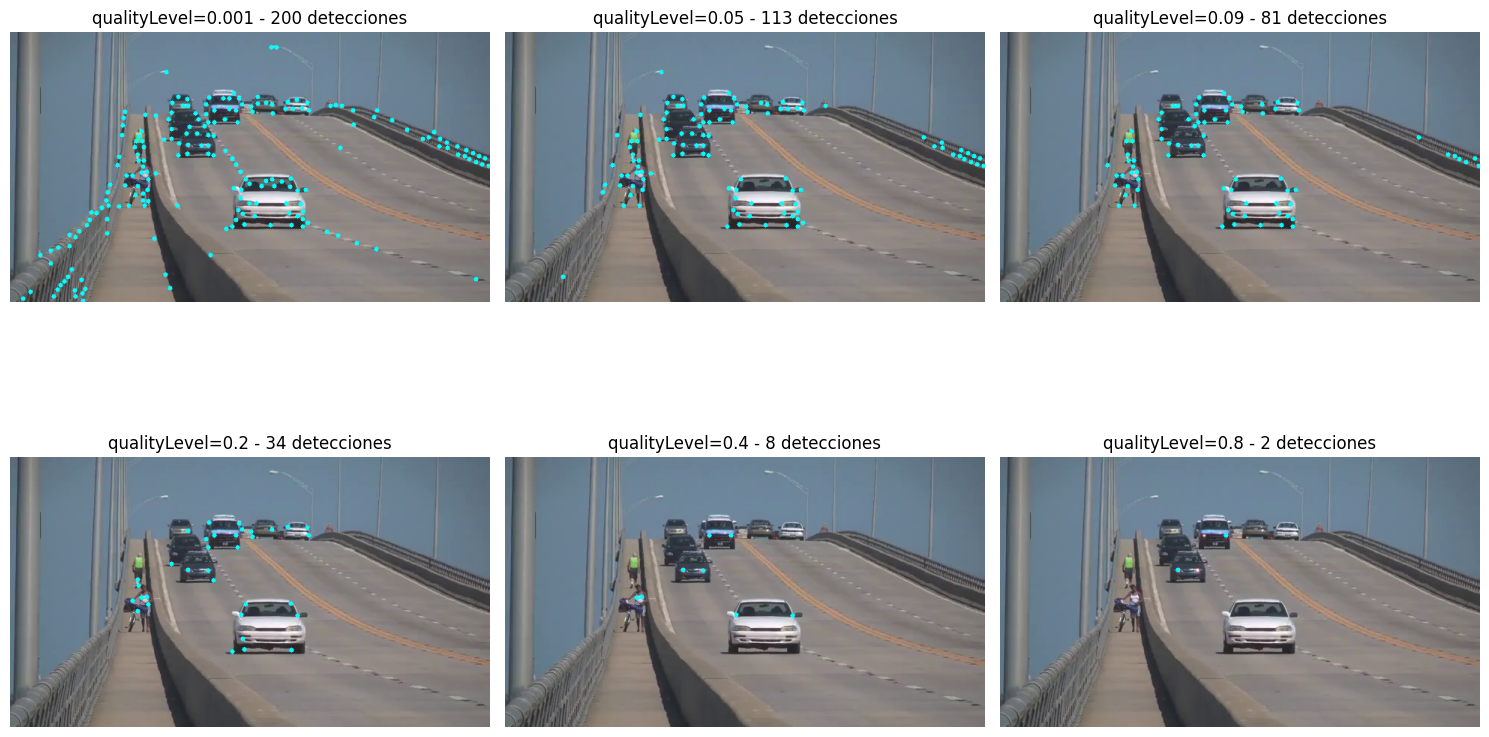

In [26]:
# Usamos el primer frame del vídeo ya cargado
import matplotlib.pyplot as plt

frame0 = frames[0]
gray = cv2.cvtColor(frame0, cv2.COLOR_BGR2GRAY)

quality_levels = [0.001, 0.05, 0.09, 0.2, 0.4, 0.8]
maxCorners = 200
minDistance = 7
blockSize = 7

plt.figure(figsize=(15, 10))

for idx, ql in enumerate(quality_levels):
    pts = cv2.goodFeaturesToTrack(
        gray,
        maxCorners=maxCorners,
        qualityLevel=ql,
        minDistance=minDistance,
        blockSize=blockSize
    )

    vis = frame0.copy()
    if pts is not None:
        pts_int = np.intp(pts)
        for x, y in pts_int.reshape(-1, 2):
            cv2.circle(vis, (x, y), 3, (255, 255, 0), -1)

        print(f"qualityLevel={ql}: {len(pts_int)} puntos detectados")
    else:
        print(f"qualityLevel={ql}: 0 puntos detectados")

    vis_rgb = cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)
    plt.subplot(2, 3, idx + 1)
    plt.imshow(vis_rgb)
    plt.title(f"qualityLevel={ql} - {len(pts_int)} detecciones")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Observaciones y extracción de conclusiones sobre el significado del qualityLevel:

Como ya hemos mencionado, el parámetro **`qualityLevel`** en la función `cv2.goodFeaturesToTrack` controla la *calidad mínima* que debe tener un punto para ser aceptado como punto de interés según el criterio de Shi-Tomasi. El algoritmo calcula primero la respuesta de calidad de todas las esquinas candidatas existentes en la imagen y obtiene la calidad máxima. A partir de ese valor, `qualityLevel` fija un umbral proporcional y sólo los puntos cuya calidad supera ese umbral se consideran puntos de interés.  

Como consecuencia de esto:

- **Valores pequeños de `qualityLevel`** : mayor número de puntos detectados, incluyendo esquinas débiles o inestables.  
- **Valores grandes de `qualityLevel`** : detección muy selectiva, limitándose a las esquinas más robustas y bien definidas.

Los resultados obtenidos mediante el código proporcionado ilustran muy claramente este comportamiento.

##### **qualityLevel = 0.001 : 200 detecciones**
El umbral es extremadamente bajo, por lo que prácticamente cualquier variación de intensidad es aceptada como punto de interés. La imagen muestra multitud de detecciones distribuidas por todas las superficies, incluyendo bordes suaves, zonas con textura leve e incluso ruido.  
Es la configuración más densa, pero también la menos fiable.

##### **qualityLevel = 0.05 : 113 detecciones**
El aumento del umbral filtra muchas detecciones débiles. Los puntos comienzan a concentrarse en bordes mejor definidos de la carretera, los coches y las barandillas. La densidad sigue siendo alta, pero el conjunto es más coherente y estable.

##### **qualityLevel = 0.09 : 81 detecciones**
A partir de este valor se observa una clara eliminación de puntos ruidosos. La mayoría de detecciones pertenecen a esquinas reales: contornos de vehículos, uniones estructurales y zonas de alto contraste.  
Es una configuración equilibrada para aplicaciones de seguimiento.


##### **qualityLevel = 0.2 : 34 detecciones**
El criterio empieza a ser bastante exigente. La imagen sólo muestra puntos localizados en estructuras claramente definidas. Aunque el número disminuye notablemente, la calidad de cada punto es superior.

##### **qualityLevel = 0.4 : 8 detecciones**
Aquí aparecen únicamente las mejores esquinas de toda la escena. Son puntos extremadamente robustos frente a cambios ligeros de luz o ruido. Sin embargo, su número es demasiado reducido para un seguimiento denso.


##### **qualityLevel = 0.8 : 2 detecciones**
Con un umbral tan alto, solo sobreviven los dos puntos de mayor calidad de toda la imagen.  
Estos puntos son muy estables, pero insuficientes para la mayoría de aplicaciones prácticas, como estimación de movimiento o reconstrucción.

## Conclusión

El análisis muestra que `qualityLevel` determina el compromiso entre cantidad y fiabilidad de los puntos detectados:

- **Umbral bajo** : detección masiva, baja estabilidad.  
- **Umbral medio (0.05–0.1)** : equilibrio entre cobertura y robustez.  
- **Umbral alto (≥0.4)** : muy pocos puntos, pero extremadamente fiables.

La elección del valor adecuado depende del tipo de tarea: para *tracking* suele preferirse un rango intermedio, mientras que para análisis estructural o detección precisa de esquinas es preferible usar valores más altos.


### Exploraciones adicionales con otro video:

Adicionalmente, hemos decidido realizar el análisis del flujo óptico utilizando otro video externo que hemos buscado por internet, aplicando lo que hemos aprendido en los apartados anteriores y viendo qué tal funciona el proceso empleado pero esta vez en un video de otros coches pasando por una carretera desde otro ángulo distinto.

In [27]:
videopath = "../data/partC/extra_vehiculos_flujo_optico.mp4"  # Path to the video file
cap = cv2.VideoCapture(filename=videopath)  # Complete this line to read the video file

# Check if the video was successfully opened
if not cap.isOpened():
    print('Error: Could not open the video file')
    os._exit(0)

# Get the szie of frames and the frame rate of the video
frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
frame_rate = cap.get(cv2.CAP_PROP_FPS)

# Añadimos un print para mostrar las características del video con el que estamos trabajando
print("Video properties:")
print(" - Width :", frame_width)
print(" - Height:", frame_height)
print(" - FPS   :", frame_rate)

frames = []
while True:
    ret, frame = cap.read() # Esto me permite leer cada uno de los frames que componen el video (al final el vídeo es una sucesión de imágenes)
    if not ret:
        break
    frames.append(frame)


cap.release()

winSize=(15, 15)
maxLevel=2
criteria= (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03)

Video properties:
 - Width : 1280
 - Height: 720
 - FPS   : 25.0


In [28]:
# Detect the initial points of interest in the first frame

# Convert the first frame to grayscale
prev_gray = cv2.cvtColor(src=frames[0], code=cv2.COLOR_BGR2GRAY)

# Define the parameters of the Shi-Tomasi algorithm
mask = None  # sirve por si queremos restringir la detección a una región específica de la imagen
maxCorners = 200  # Número máximo de corners que queremos detectar
qualityLevel = 0.3  # Calidad mínima requerida para que se considere que un punto es "bueno" y lo detecte
minDistance = 7  # Distancia mínima entre puntos detectados
blockSize = 7  # Tamaño del vecindario usado para evaluar si el punto es corner o no

# Use the function goodFeaturesToTrack to detect the points of interest
p0 = cv2.goodFeaturesToTrack(prev_gray, mask=mask, maxCorners=maxCorners, qualityLevel=qualityLevel, minDistance=minDistance, blockSize=blockSize)


In [29]:
#TODO: Use a loop to track the points of interest in the rest of the frames

# Create a mask image for drawing purposes
frame = frames[0]
mask = np.zeros_like(frame)

for i, frame in enumerate(frames[1:]):
    input_frame = frame
    # Convert the frame to grayscale
    frame_gray = cv2.cvtColor(input_frame, cv2.COLOR_BGR2GRAY)
    # Calculate the optical flow using the Lucas-Kanade algorithm

    p1, st, err = cv2.calcOpticalFlowPyrLK(prevImg=prev_gray, nextImg=frame_gray, prevPts=p0, nextPts=None)

    # Select the points that were successfully tracked
    good_new = p1[st == 1]
    good_old = p0[st == 1]

    # Draw the tracks
    for i, (new, old) in enumerate(zip(good_new, good_old)):
        a, b = new.ravel().astype(int)
        c, d = old.ravel().astype(int)
        input_frame = cv2.circle(input_frame, (a, b), 5, (0, 0, 255), -1)
        mask = cv2.line(mask, (a, b), (c, d), (0, 255, 0), 2)

    # Update the inputs for the next iteration
    prev_gray = frame_gray.copy()
    p0 = good_new.reshape(-1, 1, 2)
    
    # Show the frame with the tracks
    cv2.imshow('Visualizacion Flujo Optico Video Extra', cv2.add(input_frame, mask))
    key = cv2.waitKey(10)
    if key == ord('q'):
        break

cv2.destroyAllWindows()

## Apartado E: Filtro de Kalman para Seguimiento de Objetos

### Tarea E.1: Configuración del Filtro de Kalman

Inicializa el filtro de Kalman (cv2.KalmanFilter) con una matriz de medición y transición adecuada para un seguimiento en dos dimensiones.

In [30]:
#TODO: Use VideoCapture from OpenCV to read the video (slow_traffic_small.mp4)
videopath = "../data/partC/slow_traffic_small.mp4" # Path to the video file
cap = cv2.VideoCapture(videopath)  # Complete this line to read the video file
 
#TODO: Check if the video was successfully opened
if not cap.isOpened():
    print('Error: Could not open the video file')
 
#TODO: Get the szie of frames and the frame rate of the video
frame_width = cap.get(cv2.CAP_PROP_FRAME_WIDTH)
frame_height = cap.get(cv2.CAP_PROP_FRAME_HEIGHT)
frame_rate = cap.get(cv2.CAP_PROP_FPS)
 
#TODO: Use a loop to read the frames of the video and store them in a list
frames = []
while True:
    ret, frame = cap.read()
    if not ret:
        break
    frames.append(frame)
 
 
cap.release()
 
 
# TODO: Create the Kalman filter object
kf = cv2.KalmanFilter(4, 2) # 4 state variables, 2 measurement variables
# TODO: Initialize the state of the Kalman filter
kf.measurementMatrix = np.array([[1, 0, 0, 0], [0, 1, 0, 0]], np.float32) # Measurement matrix np.array of shape (2, 4) and type np.float32
kf.transitionMatrix = np.array([[1, 0, 1, 0], [0, 1, 0, 1], [0, 0, 1, 0], [0, 0, 0, 1]], np.float32) # Transition matrix np.array of shape (4, 4) and type np.float32
kf.processNoiseCov = np.eye(4, dtype=np.float32) * 0.01 # Process noise covariance np.array of shape (4, 4) and type np.float32
 
measurement = np.array((2, 1), np.float32)
prediction = np.zeros((2, 1), np.float32)
 
#TODO: Show the frames to select the initial position of the object
 
for i, frame in enumerate(frames):
    # Show the frame
    cv2.imshow('Frame', frame)
    # Wait for the key
    key = cv2.waitKey(0)
    print(key)
    # If the key is 'n' continue to the next frame
    if key == ord('n'):
        continue
    # If the key is 's' select the position of the object
    elif key == ord('s'):
        # Select the position of the object
        x, y, w, h = cv2.selectROI('Frame', frame, False)
        track_window = (x, y, w, h)
        #TODO: Compute the center of the object
        cx = x + w // 2
        cy = y + h // 2
        print(f'Center of the object: {cx}, {cy}')
        #TODO: Initialize the state of the Kalman filter
        kf.statePost = np.array([[cx], [cy], [0], [0]], np.float32)
        # Initialize the covariance matrix
        kf.errorCovPost = np.eye(4, dtype=np.float32)
        #Predict the position of the object
        prediction = kf.predict()
 
        #TODO: Update the measurement and correct the Kalman filter
        measurement = np.array([[cx], [cy]], np.float32)
        kf.correct(measurement)
 
        #TODO: Crop the object
        crop = frame[y:y+h, x:x+w].copy()  # Recorta exactamente el ROI seleccionado
       
        hsv_crop = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
        #TODO: Compute the histogram of the cropped object (Reminder: Use only the Hue channel (0-180))
        mask = cv2.inRange(hsv_crop, np.array([0, 50, 50]), np.array([180, 255, 255]))
        crop_hist = cv2.calcHist([hsv_crop], [0], mask=mask, histSize=[180], ranges=[0, 180])
        cv2.normalize(crop_hist, crop_hist, 0, 255, cv2.NORM_MINMAX)
       
        print(f'Initial position selected: {x}, {y}')
        break
 
cv2.destroyAllWindows()

113
115
Center of the object: 173, 144
Initial position selected: 167, 136


### Tarea E.2: Predicción y Corrección del Estado

Realiza la predicción del estado y corrige la posición estimada en cada iteración.

In [31]:
#TODO: Use the Kalman filter to predict the position of the points of interest
 
term_crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 1)
 
for frame in frames[i:]:
    #TODO: Copy the frame
    input_frame = frame.copy()
    #TODO: Convert the frame to HSV
    img_hsv = cv2.cvtColor(input_frame, cv2.COLOR_BGR2HSV)
   
    # Compute the back projection of the histogram
    img_bproject = cv2.calcBackProject([img_hsv], [0], crop_hist, [0, 180], 1)
   
    # Apply the mean shift algorithm to the back projection
    ret, track_window = cv2.meanShift(img_bproject, track_window, term_crit)
    x_,y_,w_,h_ = track_window
    #TODO: Compute the center of the object
    c_x = x_ + w_ // 2
    c_y = y_ + h_ // 2
   
    # Predict the position of the object
    prediction = kf.predict()
 
    #TODO: Update the measurement and correct the Kalman filter
    measurement = np.array([[c_x], [c_y]], np.float32)
    kf.correct(measurement)
 
   
    # Draw the predicted position as RED rectangle (same size as original)
    pred_x = int(prediction[0][0] - w_ // 2)
    pred_y = int(prediction[1][0] - h_ // 2)
    cv2.rectangle(input_frame, (pred_x, pred_y), (pred_x + w_, pred_y + h_), (0, 0, 255), 2)
   
    # Draw the measured position as GREEN rectangle (same size as original)
    cv2.rectangle(input_frame, (x_, y_), (x_ + w_, y_ + h_), (0, 255, 0), 2)
   
    # También mantener los círculos (opcional)
    cv2.circle(input_frame, (int(prediction[0][0]), int(prediction[1][0])), 5, (0, 0, 255), -1)
    cv2.circle(input_frame, (int(c_x), int(c_y)), 5, (0, 255, 0), -1)
   
    # Show the frame with the predicted position
    cv2.imshow('Frame', input_frame)
    key = cv2.waitKey(0)
    if key == ord('q'):
        break
 
cv2.destroyAllWindows()

**Preguntas del Apartado E**
1. ¿Cómo afecta el valor de `transitionMatrix` a la predicción en el filtro de Kalman?
2. ¿Cuál es la diferencia entre `measurementMatrix` y `transitionMatrix` en el contexto del seguimiento de objetos?

### Pregunta E1 

En un Filtro de Kalman, la matriz de transición de estados (transitionMatrix, normalmente denotada como F) define cómo evoluciona el estado del sistema entre un instante de tiempo y el siguiente.

La transitionMatrix describe matemáticamente cómo se pasa del estado en el frame t al estado en el frame t+1.

En nuestro caso, el valor de este parámetro que hemos seleccionado se trata de una matriz que representa un modelo de movimiento lineal uniforme, donde la posición en el siguiente frame es la posición actual sumado a la velocidad (multiplicada por el incremento de tiempo, que aquí se considera 1)

#### ¿Cómo influye modificar la transitionMatrix?

El valor clave que suele variarse es el factor de velocidad (los valores que están en la matriz en [0,2] y [1,3], que en nuestro caso los habíamos dejado iguales a 1).

Si el factor de velocidad es mayor que 1:

- El filtro asume que el objeto se mueve más rápido.

- La predicción avanza más y se vuelve más agresiva.
 
- Puede adelantarse al objeto incluso si MeanShift no detecta movimiento.

- Útil si el objeto realmente acelera o se desplaza rápido.

- Perjudicial si el objeto se mueve lento, genera predicciones incorrectas.

Si el factor de velocidad es menor que 1:

- La contribución de la velocidad se reduce.

- Las predicciones son suaves y conservadoras.

- El filtro sigue muy de cerca las mediciones, confiando menos en el modelo dinámico.

- Útil cuando el movimiento es lento o errático.

- No adecuado para objetos en movimiento rápido, la predicción se queda corta.

Si el factor es exactamente 1:

- Es el modelo estándar.

- Movimiento lineal uniforme con incremento de tiempo igual a 1.

- Balance adecuado para movimientos realistas sin aceleración.

En general, el hiperparámetro de transitionMatrix controla cómo cree el Kalman que se mueve el objeto, y ajustar el parámetro asociado al componente de velocidad permite obtener predicciones más agresivas o más suaves dependiendo de la naturaleza del movimiento. Un barrido de este único parámetro permite observar claramente cómo el Kalman adelanta, retrasa o equilibra la trayectoria.


---

### Probamos a repetir el proceso usando distintos valores de transitionMatrix para analizar los resultados:



#### Prueba con una velocidad "más alta":

In [32]:
# TODO: Create the Kalman filter object
kf = cv2.KalmanFilter(4, 2) # 4 state variables, 2 measurement variables
# TODO: Initialize the state of the Kalman filter
kf.measurementMatrix = np.array([[1, 0, 0, 0], [0, 1, 0, 0]], np.float32) # Measurement matrix np.array of shape (2, 4) and type np.float32
kf.transitionMatrix = np.array([[1, 0, 2, 0], [0, 1, 0, 2], [0, 0, 1, 0], [0, 0, 0, 1]], np.float32) # Transition matrix np.array of shape (4, 4) and type np.float32
kf.processNoiseCov = np.eye(4, dtype=np.float32) * 0.01 # Process noise covariance np.array of shape (4, 4) and type np.float32
 
measurement = np.array((2, 1), np.float32)
prediction = np.zeros((2, 1), np.float32)
 
#TODO: Show the frames to select the initial position of the object
 
for i, frame in enumerate(frames):
    # Show the frame
    cv2.imshow('Frame', frame)
    # Wait for the key
    key = cv2.waitKey(0)
    print(key)
    # If the key is 'n' continue to the next frame
    if key == ord('n'):
        continue
    # If the key is 's' select the position of the object
    elif key == ord('s'):
        # Select the position of the object
        x, y, w, h = cv2.selectROI('Frame', frame, False)
        track_window = (x, y, w, h)
        #TODO: Compute the center of the object
        cx = x + w // 2
        cy = y + h // 2
        print(f'Center of the object: {cx}, {cy}')
        #TODO: Initialize the state of the Kalman filter
        kf.statePost = np.array([[cx], [cy], [0], [0]], np.float32)
        # Initialize the covariance matrix
        kf.errorCovPost = np.eye(4, dtype=np.float32)
        #Predict the position of the object
        prediction = kf.predict()
 
        #TODO: Update the measurement and correct the Kalman filter
        measurement = np.array([[cx], [cy]], np.float32)
        kf.correct(measurement)
 
        #TODO: Crop the object
        crop = frame[y:y+h, x:x+w].copy()  # Recorta exactamente el ROI seleccionado
       
        hsv_crop = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
        #TODO: Compute the histogram of the cropped object (Reminder: Use only the Hue channel (0-180))
        mask = cv2.inRange(hsv_crop, np.array([0, 50, 50]), np.array([180, 255, 255]))
        crop_hist = cv2.calcHist([hsv_crop], [0], mask=mask, histSize=[180], ranges=[0, 180])
        cv2.normalize(crop_hist, crop_hist, 0, 255, cv2.NORM_MINMAX)
       
        print(f'Initial position selected: {x}, {y}')
        break
 
cv2.destroyAllWindows()

113
115
Center of the object: 180, 152
Initial position selected: 147, 135


In [33]:
#TODO: Use the Kalman filter to predict the position of the points of interest
 
term_crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 1)
 
for frame in frames[i:]:
    #TODO: Copy the frame
    input_frame = frame.copy()
    #TODO: Convert the frame to HSV
    img_hsv = cv2.cvtColor(input_frame, cv2.COLOR_BGR2HSV)
   
    # Compute the back projection of the histogram
    img_bproject = cv2.calcBackProject([img_hsv], [0], crop_hist, [0, 180], 1)
   
    # Apply the mean shift algorithm to the back projection
    ret, track_window = cv2.meanShift(img_bproject, track_window, term_crit)
    x_,y_,w_,h_ = track_window
    #TODO: Compute the center of the object
    c_x = x_ + w_ // 2
    c_y = y_ + h_ // 2
   
    # Predict the position of the object
    prediction = kf.predict()
 
    #TODO: Update the measurement and correct the Kalman filter
    measurement = np.array([[c_x], [c_y]], np.float32)
    kf.correct(measurement)
 
   
    # Draw the predicted position as RED rectangle (same size as original)
    pred_x = int(prediction[0][0] - w_ // 2)
    pred_y = int(prediction[1][0] - h_ // 2)
    cv2.rectangle(input_frame, (pred_x, pred_y), (pred_x + w_, pred_y + h_), (0, 0, 255), 2)
   
    # Draw the measured position as GREEN rectangle (same size as original)
    cv2.rectangle(input_frame, (x_, y_), (x_ + w_, y_ + h_), (0, 255, 0), 2)
   
    # También mantener los círculos (opcional)
    cv2.circle(input_frame, (int(prediction[0][0]), int(prediction[1][0])), 5, (0, 0, 255), -1)
    cv2.circle(input_frame, (int(c_x), int(c_y)), 5, (0, 255, 0), -1)
   
    # Show the frame with the predicted position
    cv2.imshow('Frame', input_frame)
    key = cv2.waitKey(0)
    if key == ord('q'):
        break
 
cv2.destroyAllWindows()

### Prueba velocidad "más baja":

In [34]:
# TODO: Create the Kalman filter object
kf = cv2.KalmanFilter(4, 2) # 4 state variables, 2 measurement variables
# TODO: Initialize the state of the Kalman filter
kf.measurementMatrix = np.array([[1, 0, 0, 0], [0, 1, 0, 0]], np.float32) # Measurement matrix np.array of shape (2, 4) and type np.float32
kf.transitionMatrix = np.array([[1, 0, 1, 0], [0, 1, 0, 1], [0, 0, 0.5, 0], [0, 0, 0, 0.5]], np.float32) # Transition matrix np.array of shape (4, 4) and type np.float32
kf.processNoiseCov = np.eye(4, dtype=np.float32) * 0.01 # Process noise covariance np.array of shape (4, 4) and type np.float32
 
measurement = np.array((2, 1), np.float32)
prediction = np.zeros((2, 1), np.float32)
 
#TODO: Show the frames to select the initial position of the object
 
for i, frame in enumerate(frames):
    # Show the frame
    cv2.imshow('Frame', frame)
    # Wait for the key
    key = cv2.waitKey(0)
    print(key)
    # If the key is 'n' continue to the next frame
    if key == ord('n'):
        continue
    # If the key is 's' select the position of the object
    elif key == ord('s'):
        # Select the position of the object
        x, y, w, h = cv2.selectROI('Frame', frame, False)
        track_window = (x, y, w, h)
        #TODO: Compute the center of the object
        cx = x + w // 2
        cy = y + h // 2
        print(f'Center of the object: {cx}, {cy}')
        #TODO: Initialize the state of the Kalman filter
        kf.statePost = np.array([[cx], [cy], [0], [0]], np.float32)
        # Initialize the covariance matrix
        kf.errorCovPost = np.eye(4, dtype=np.float32)
        #Predict the position of the object
        prediction = kf.predict()
 
        #TODO: Update the measurement and correct the Kalman filter
        measurement = np.array([[cx], [cy]], np.float32)
        kf.correct(measurement)
 
        #TODO: Crop the object
        crop = frame[y:y+h, x:x+w].copy()  # Recorta exactamente el ROI seleccionado
       
        hsv_crop = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
        #TODO: Compute the histogram of the cropped object (Reminder: Use only the Hue channel (0-180))
        mask = cv2.inRange(hsv_crop, np.array([0, 50, 50]), np.array([180, 255, 255]))
        crop_hist = cv2.calcHist([hsv_crop], [0], mask=mask, histSize=[180], ranges=[0, 180])
        cv2.normalize(crop_hist, crop_hist, 0, 255, cv2.NORM_MINMAX)
       
        print(f'Initial position selected: {x}, {y}')
        break
 
cv2.destroyAllWindows()

115
Center of the object: 180, 144
Initial position selected: 162, 129


In [35]:
#TODO: Use the Kalman filter to predict the position of the points of interest
 
term_crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 1)
 
for frame in frames[i:]:
    #TODO: Copy the frame
    input_frame = frame.copy()
    #TODO: Convert the frame to HSV
    img_hsv = cv2.cvtColor(input_frame, cv2.COLOR_BGR2HSV)
   
    # Compute the back projection of the histogram
    img_bproject = cv2.calcBackProject([img_hsv], [0], crop_hist, [0, 180], 1)
   
    # Apply the mean shift algorithm to the back projection
    ret, track_window = cv2.meanShift(img_bproject, track_window, term_crit)
    x_,y_,w_,h_ = track_window
    #TODO: Compute the center of the object
    c_x = x_ + w_ // 2
    c_y = y_ + h_ // 2
   
    # Predict the position of the object
    prediction = kf.predict()
 
    #TODO: Update the measurement and correct the Kalman filter
    measurement = np.array([[c_x], [c_y]], np.float32)
    kf.correct(measurement)
 
   
    # Draw the predicted position as RED rectangle (same size as original)
    pred_x = int(prediction[0][0] - w_ // 2)
    pred_y = int(prediction[1][0] - h_ // 2)
    cv2.rectangle(input_frame, (pred_x, pred_y), (pred_x + w_, pred_y + h_), (0, 0, 255), 2)
   
    # Draw the measured position as GREEN rectangle (same size as original)
    cv2.rectangle(input_frame, (x_, y_), (x_ + w_, y_ + h_), (0, 255, 0), 2)
   
    # También mantener los círculos (opcional)
    cv2.circle(input_frame, (int(prediction[0][0]), int(prediction[1][0])), 5, (0, 0, 255), -1)
    cv2.circle(input_frame, (int(c_x), int(c_y)), 5, (0, 255, 0), -1)
   
    # Show the frame with the predicted position
    cv2.imshow('Frame', input_frame)
    key = cv2.waitKey(0)
    if key == ord('q'):
        break
 
cv2.destroyAllWindows()

### Gráfico de comparación de precisión según los valores de velocidad usados:

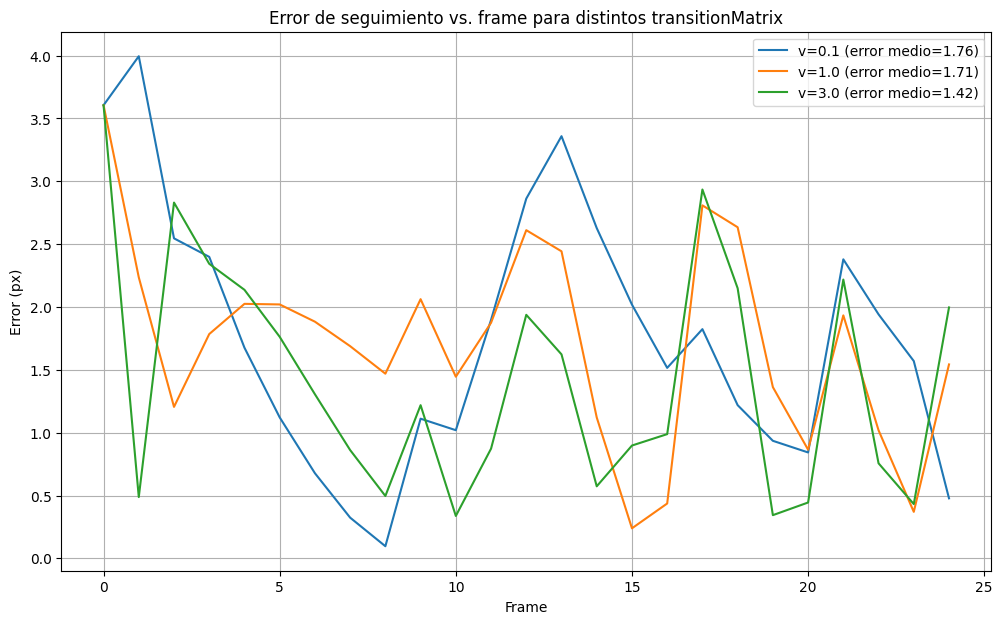

In [36]:
import matplotlib.pyplot as plt

# ===========================
# Seleccionamos ROI inicial
# ===========================
frame0 = frames[0]
x, y, w, h = cv2.selectROI("Frame", frame0, False)
cv2.destroyAllWindows()

cx, cy = x + w//2, y + h//2

# Histograma del objeto
crop = frame0[y:y+h, x:x+w]
hsv_crop = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
mask = cv2.inRange(hsv_crop, np.array([0,50,50]), np.array([180,255,255]))
crop_hist = cv2.calcHist([hsv_crop], [0], mask, [180], [0,180])
cv2.normalize(crop_hist, crop_hist, 0, 255, cv2.NORM_MINMAX)

# ===========================
# Parámetros a barrer (solo transitionMatrix)
# ===========================
velocity_factors = [0.1, 1.0, 3.0]
term_crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 20, 1)

all_errors = {}

# ===========================
# CÁLCULO DEL ERROR
# ===========================
for v in velocity_factors:
    
    kf = cv2.KalmanFilter(4, 2)
    kf.measurementMatrix = np.array([[1,0,0,0],[0,1,0,0]], np.float32)

    # transición modificada según el parámetro
    kf.transitionMatrix = np.array([
        [1,0,v,0],
        [0,1,0,v],
        [0,0,1,0],
        [0,0,0,1]
    ], np.float32)

    kf.processNoiseCov = np.eye(4, dtype=np.float32) * 0.01
    kf.measurementNoiseCov = np.eye(2, dtype=np.float32) * 1.0

    kf.statePost = np.array([[cx],[cy],[0],[0]], np.float32)
    kf.errorCovPost = np.eye(4, dtype=np.float32)

    track_window = (x,y,w,h)
    
    errors = []

    for frame in frames[:25]:
        hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
        backproj = cv2.calcBackProject([hsv],[0],crop_hist,[0,180],1)
        _, track_window = cv2.meanShift(backproj, track_window, term_crit)

        xx, yy, ww, hh = track_window
        mx, my = xx + ww//2, yy + hh//2

        pred = kf.predict()
        measurement = np.array([[mx],[my]], np.float32)
        kf.correct(measurement)

        # error euclídeo
        err = np.linalg.norm(np.array([pred[0][0]-mx, pred[1][0]-my]))
        errors.append(err)

    all_errors[v] = errors

# ===========================
# GRÁFICO DEL ERROR
# ===========================
plt.figure(figsize=(12, 7))

for v, errors in all_errors.items():
    plt.plot(errors, label=f"v={v} (error medio={np.mean(errors):.2f})")

plt.xlabel("Frame")
plt.ylabel("Error (px)")
plt.title("Error de seguimiento vs. frame para distintos transitionMatrix")
plt.legend()
plt.grid(True)
plt.show()


### Almacenamiento de la imagen resultante

Como para cada ejecución distinta del código de la celda superior, se puede generar un resultado diferente, hemos decidido guardar un resultado de ejemplo en la carpeta data/partC/Extra_Results , también de cara a meterla en la memoria.

---

El gráfico muestra claramente cómo el parámetro asociado a la transición del estado en el filtro de Kalman, concretamente el factor que multiplica a la velocidad en la transitionMatrix, influye directamente en la capacidad del modelo para predecir la posición del objeto entre frames. Cuando el valor es bajo, como en v = 0.1, el filtro asume que el objeto prácticamente no se mueve entre un frame y el siguiente, lo que genera predicciones demasiado conservadoras. 

Esto provoca que el filtro dependa excesivamente de la medición obtenida mediante meanShift, y como consecuencia el error es elevado y altamente fluctuante, especialmente en escenas donde el objeto se desplaza de forma apreciable. Al aumentar el parámetro a v = 1.0 el modelo incorpora una dinámica de movimiento más realista, de modo que la predicción previa se aproxima más al movimiento real del objeto. Esto se manifiesta en una reducción significativa del error medio y una mayor estabilidad a lo largo de los frames, ya que el filtro combina de forma más equilibrada la predicción y la medida. 

Cuando se incrementa aún más el valor hasta v = 3.0 el modelo se vuelve más “proactivo”, anticipando desplazamientos más rápidos. Aunque esto puede parecer beneficioso, un valor excesivo provoca que el filtro tienda a sobreestimar el movimiento, generando predicciones que pueden adelantarse demasiado a la posición real. Aun así, en este caso concreto el error medio continúa siendo bajo y se observa un comportamiento relativamente estable, lo que indica que para este vídeo existe un rango relativamente amplio de valores que permiten un seguimiento razonablemente preciso. 

En conjunto, esta prueba de distintos valores de transitionMatrix muestra que la elección del parámetro de transición condiciona de forma crucial la calidad del seguimiento: valores demasiado pequeños hacen que el filtro reaccione tarde, mientras que valores excesivamente altos pueden introducir inestabilidad si el movimiento real no coincide con la dinámica asumida. Un ajuste adecuado proporciona predicciones suaves que reducen el error y mejoran la continuidad temporal del seguimiento.


### Pregunta E2: